Classes: ['cats', 'dogs']
Training images: 2
Validation images: 2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5


C:\Users\Rujuta\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2/2 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.0000e+00 - loss: 2.9739 - val_accuracy: 0.5000 - val_loss: 1.2362
Epoch 2/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 129ms/step - accuracy: 0.0000e+00 - loss: 2.0913 - val_accuracy: 0.5000 - val_loss: 0.9783
Epoch 3/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.5000 - loss: 1.4085 - val_accuracy: 0.5000 - val_loss: 0.7694
Epoch 4/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.5000 - loss: 0.8637 - val_accuracy: 0.5000 - val_loss: 0.6128
Epoch 5/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.5000 - loss: 0.4742 - val_accuracy: 1.0000 - val_loss: 0.5174
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 1.0000 - loss: 0.5174
Validation Accuracy: 100.0 %
Validation Loss: 0.5174


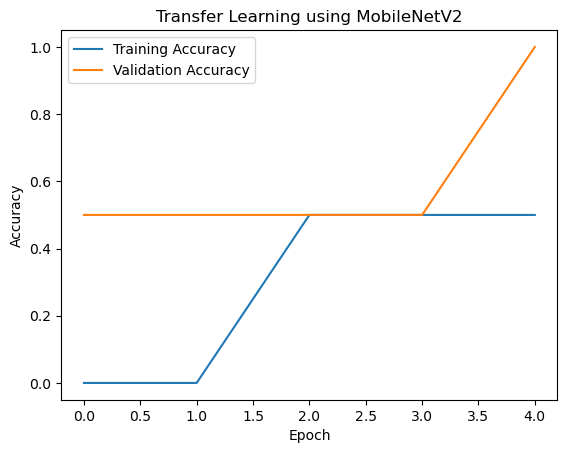

In [4]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

# Step 1: Load images from the folders
path = r"C:\Users\Rujuta\Documents\3rd Year\Sem 5\DIP\dataset"

class_names = ["cats", "dogs"]

train_images = []
train_labels = []
val_images = []
val_labels = []

# Use one image per class for training
# and one image per class for validation
for label, folder in enumerate(class_names):
    folder_path = os.path.join(path, folder)

    files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".gif"))
    ])

    if len(files) < 2:
        raise ValueError(
            f"At least 2 supported images are needed in {folder_path}"
        )

    for i, file in enumerate(files):
        image_path = os.path.join(folder_path, file)

        image = tf.keras.utils.load_img(
            image_path, target_size=(160, 160)
        )
        image = tf.keras.utils.img_to_array(image)

        if i == 0:
            train_images.append(image)
            train_labels.append(label)
        else:
            val_images.append(image)
            val_labels.append(label)

train_data = tf.data.Dataset.from_tensor_slices(
    (train_images, train_labels)
).batch(1)

val_data = tf.data.Dataset.from_tensor_slices(
    (val_images, val_labels)
).batch(1)

print("Classes:", class_names)
print("Training images:", len(train_images))
print("Validation images:", len(val_images))

# Step 2: Load pre-trained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

# Step 3: Freeze the pre-trained layers
base_model.trainable = False

# Step 4: Build the transfer learning model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(160, 160, 3)),
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(2, activation="softmax")
])

# Step 5: Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Step 6: Train the model
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

# Step 7: Evaluate the model
loss, accuracy = model.evaluate(val_data)

print("Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Validation Loss:", round(loss, 4))

# Step 8: Plot accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Transfer Learning using MobileNetV2")
plt.legend()
plt.show()